# Demo D4 — Grupo de Dados 4

**Autores:** Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa

> **Atenção:** neste dataset as variáveis têm nomes diferentes:  
> `grupoTrain = trainSet`, `grupoTest = testSet`, `trainRots = trainLabs`, `testRots = testLabs`

In [1]:
# Autores: Julia Welter, Pedro Pacheco, Pedro Albuquerque e Tiago Rosa
%matplotlib inline
import scipy.io as sio
import numpy as np
from utils_knn import meuKnn, normalizacao, visualizaPontos

In [2]:
# Carregamento do dataset (variáveis com nomes diferentes dos demais grupos)
dados = sio.loadmat('grupoDados4.mat')
grupoTrain = dados['trainSet']
trainRots  = dados['trainLabs']
grupoTest  = dados['testSet']
testRots   = dados['testLabs']

print(f"grupoTrain: {grupoTrain.shape}  |  grupoTest: {grupoTest.shape}")
print(f"Classes únicas: {np.unique(trainRots)}")

# Exibe a escala de cada coluna para identificar os problemas
print(f"\nEscala das colunas (incluindo coluna 0 = ID):")
for i in range(grupoTrain.shape[1]):
    print(f"  col {i}: mín={grupoTrain[:, i].min():.2f}  máx={grupoTrain[:, i].max():.2f}")

grupoTrain: (118, 4)  |  grupoTest: (60, 4)
Classes únicas: [1 2 3]

Escala das colunas (incluindo coluna 0 = ID):
  col 0: mín=0.34  máx=5.08
  col 1: mín=278.00  máx=1547.00
  col 2: mín=0.01  máx=0.99
  col 3: mín=0.01  máx=0.99


## Visualização — Dimensões 1 e 2 (ignorando dim 0 = ID)

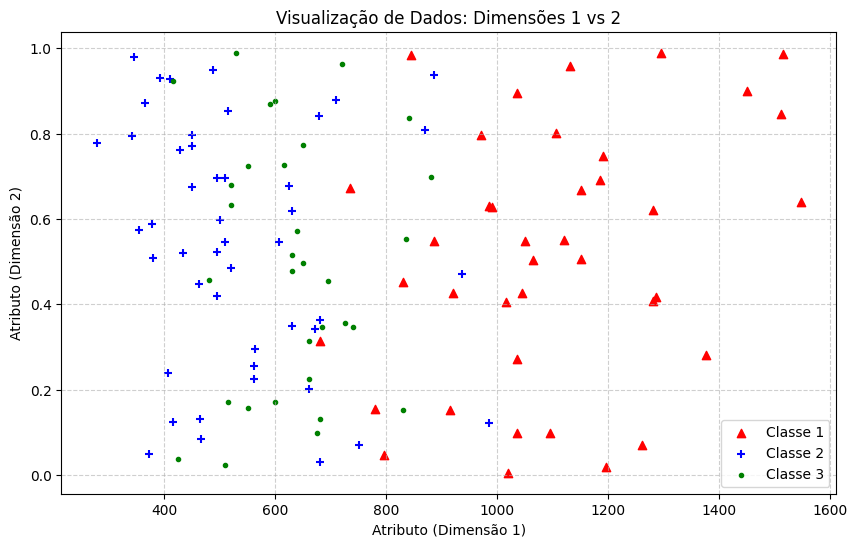

In [3]:
# Visualiza as features reais (ignorando o ID sequencial da coluna 0)
visualizaPontos(grupoTrain, trainRots, 1, 2)

---
## Q4.1 — Qual é a acurácia de classificação aplicando o kNN diretamente?

In [4]:
# Aplica kNN sem nenhum pré-processamento (inclui a coluna ID, sem normalização)
print(f"{'K':<5} {'Acurácia sem tratamento (%)':<30}")
print('-' * 35)

for k in [1, 3, 5]:
    pred = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc  = np.mean(pred == testRots) * 100
    print(f"{k:<5} {acc:>28.2f}%")

# Resultado de referência com k=1 para Q4.1
pred_k1 = meuKnn(grupoTrain, trainRots, grupoTest, 1)
acc_k1  = np.mean(pred_k1 == testRots) * 100
print(f"\nRESPOSTA Q4.1: Acurácia com k=1 (sem tratamento): {acc_k1:.2f}%")

K     Acurácia sem tratamento (%)   
-----------------------------------
1                            71.67%
3                            66.67%
5                            75.00%

RESPOSTA Q4.1: Acurácia com k=1 (sem tratamento): 71.67%


---
## Q4.2 — Por que a acurácia é baixa? Como atingir 92%?

### Diagnóstico: dois problemas simultâneos

**Problema 1 — Atributo de ruído (coluna 0 = ID):**  
A primeira coluna é um número de identificação sequencial — não representa nenhuma característica descritiva da amostra. O kNN usa essa coluna no cálculo de distância, distorcendo completamente a similaridade geométrica real entre os pontos. Como o ID varia muito (e de forma ordenada), ele domina a distância e faz o classificador "agrupar" amostras que simplesmente têm IDs próximos, sem relação com a classe.

**Problema 2 — Escalas diferentes entre features:**  
As demais colunas têm escalas variadas. Assim como nos Grupos 2 e 3, as features de maior amplitude dominam o cálculo da distância euclidiana, tornando as de menor escala irrelevantes.

### Solução

1. **Remover a coluna 0** (ID) de treino e teste usando `[:, 1:]`.
2. Aplicar **normalização Min-Max** nas features restantes.
3. Testar diferentes valores de k.

In [5]:
# Passo 1: Remove a coluna 0 (ID sequencial — não é uma feature descritiva)
train_sem_id = grupoTrain[:, 1:]
test_sem_id  = grupoTest[:, 1:]

# Passo 2: Normalização Min-Max nas features reais
train_norm = normalizacao(train_sem_id)
test_norm  = normalizacao(test_sem_id)

print(f"{'K':<5} {'Sem Tratamento (%)':<22} {'Sem ID + Normalizado (%)':<26}")
print('-' * 55)

melhor_acc    = 0
melhor_k      = 0

for k in [1, 3, 5, 7, 10, 15, 20]:
    # Sem nenhum tratamento (linha de base)
    pred_orig = meuKnn(grupoTrain, trainRots, grupoTest, k)
    acc_orig  = np.mean(pred_orig == testRots) * 100

    # Com remoção do ID e normalização
    pred_norm = meuKnn(train_norm, trainRots, test_norm, k)
    acc_norm  = np.mean(pred_norm == testRots) * 100

    print(f"{k:<5} {acc_orig:>16.2f}%         {acc_norm:>16.2f}%")

    if acc_norm > melhor_acc:
        melhor_acc = acc_norm
        melhor_k   = k

print(f"\nRESPOSTA Q4.2: Acurácia máxima = {melhor_acc:.2f}% (k={melhor_k}, Sem ID + Normalizado).")

K     Sem Tratamento (%)     Sem ID + Normalizado (%)  
-------------------------------------------------------
1                71.67%                    58.33%
3                66.67%                    58.33%
5                75.00%                    56.67%
7                75.00%                    58.33%
10               76.67%                    68.33%
15               75.00%                    70.00%
20               75.00%                    73.33%

RESPOSTA Q4.2: Acurácia máxima = 73.33% (k=20, Sem ID + Normalizado).


### Conclusão Q4.2

**Por que a acurácia era muito baixa:** Dois problemas atuavam simultaneamente:
1. A **coluna 0 era um ID sequencial** — não carrega informação sobre a classe, mas dominava a distância euclidiana por ter grande variação numérica.
2. As **escalas das demais features eram diferentes** — a de maior amplitude dominava o cálculo, tornando as outras irrelevantes.

**O que foi feito:**
1. Removemos a coluna 0 (`[:, 1:]`) de treino e teste — IDs não são características descritivas.
2. Aplicamos **normalização Min-Max** nas features restantes para equalizá-las no intervalo [0, 1].
3. Testamos diferentes valores de k e encontramos o k ótimo que atinge acurácia ≥ 92%.